# 03 · Relations

SPEC 03, roadmap 2.6 and 2.7. Train races only. Each feature against the target, the shape of that relation,
the interactions the scope document hints at, correlation between features, VIF, and a check for leakage.
Rows of one race are not independent, so every interval resamples whole races (seed of `config/training.json`).

Two row sets are shown where it matters: **all valid rows** (1,050) and the rows with **15 or more clean
laps** (1,041), the minimum that `02` suggests. The only row removed by the second set that moves a statistic
is the extreme Zandvoort target.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parents[1]
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "notebooks" / "exploratory")]

from provisional import DATASET_PATH  # noqa: E402

from common.config import load_config  # noqa: E402

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update(
    {"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False}
)
SEED = load_config().optuna.seed
rng = np.random.default_rng(SEED)
df = pd.read_parquet(DATASET_PATH)
valid = df[df["is_valid_row"]].copy()
n_races = valid[["year", "round"]].drop_duplicates().shape[0]
print(f"{len(df)} rows, {len(valid)} valid, {n_races} train races, seed {SEED}")
from scipy import stats  # noqa: E402


def race_bootstrap(stat, frame=None, draws=1000):
    """95% interval of `stat(frame)` resampling whole races, never single rows."""
    frame = valid if frame is None else frame
    key = frame["year"].astype(str) + "-" + frame["round"].astype(str)
    groups = [g.index.to_numpy() for _, g in frame.groupby(key)]
    values = []
    for _ in range(draws):
        pick = rng.integers(0, len(groups), len(groups))
        values.append(stat(frame.loc[np.concatenate([groups[i] for i in pick])]))
    return np.percentile(values, [2.5, 97.5]).round(3)


TARGET = "race_pace_delta_pct"
NUMERIC = [
    "quali_delta_pct", "grid_position", "reached_q3", "fp_long_run_delta_pct", "fp_tyre_deg",
    "driver_pace_last3", "team_pace_last3", "teammate_quali_gap", "team_pace_this_circuit_prev",
    "track_temp", "air_temp", "rain_flag", "sprint_pace_delta_pct", "is_sprint_weekend",
]  # fmt: skip
EXPLORATION_ONLY = ["humidity", "wind_speed"]
for column in NUMERIC:
    valid[column] = valid[column].astype(float)
valid["quali_cap3"] = valid["quali_delta_pct"].clip(upper=3)
firm = valid[valid["clean_laps"] >= 15]
print(len(valid), "valid rows;", len(firm), "with 15+ clean laps")

1118 rows, 1050 valid, 56 train races, seed 42


1050 valid rows; 1041 with 15+ clean laps


## 1. Each feature against the target

Pearson (linear), Spearman (monotone, robust to the extreme values) and a 95% interval for Spearman that resamples
races. `n` is the number of rows with the feature present.

In [2]:
def spearman_of(column):
    def stat(frame):
        part = frame[[column, TARGET]].dropna()
        return stats.spearmanr(part[column], part[TARGET]).statistic

    return stat


def pearson(frame, column):
    part = frame[[column, TARGET]].dropna()
    return part[column].corr(part[TARGET])


rows = []
for column in NUMERIC + EXPLORATION_ONLY:
    low, high = race_bootstrap(spearman_of(column), draws=400)
    rows.append(
        {
            "feature": column,
            "n": int(valid[column].notna().sum()),
            "pearson": pearson(valid, column),
            "pearson (15+ laps)": pearson(firm, column),
            "spearman": spearman_of(column)(valid),
            "ci_low": low,
            "ci_high": high,
        }
    )
corr = pd.DataFrame(rows).set_index("feature")
print(corr.reindex(corr["spearman"].abs().sort_values(ascending=False).index).round(3).to_string())

                                n  pearson  pearson (15+ laps)  spearman  ci_low  ci_high
feature                                                                                  
grid_position                1048    0.611               0.721     0.745   0.710    0.777
sprint_pace_delta_pct         216    0.701               0.701     0.734   0.637    0.800
driver_pace_last3            1022    0.557               0.640     0.709   0.663    0.746
quali_delta_pct              1050    0.309               0.314     0.708   0.656    0.759
team_pace_last3              1030    0.575               0.666     0.701   0.656    0.746
reached_q3                   1050   -0.510              -0.616    -0.645  -0.685   -0.599
fp_long_run_delta_pct         594    0.302               0.505     0.575   0.504    0.645
team_pace_this_circuit_prev   594    0.521               0.525     0.554   0.499    0.611
teammate_quali_gap           1040    0.127               0.090     0.206   0.165    0.248
fp_tyre_de

In [3]:
corr_cap = valid[["quali_cap3", TARGET]].corr().iloc[0, 1]
print(
    f"quali_delta_pct capped at 3%: Pearson {corr_cap:.3f} (uncapped {corr.loc['quali_delta_pct', 'pearson']:.3f}),"
    f" Spearman {spearman_of('quali_cap3')(valid):.3f}"
)
sprint_part = valid[valid["is_sprint_weekend"] == 1]
print(
    "on the",
    len(sprint_part),
    "sprint-weekend rows:",
    "Spearman(sprint_pace_delta_pct, target)",
    round(spearman_of("sprint_pace_delta_pct")(sprint_part), 3),
    race_bootstrap(spearman_of("sprint_pace_delta_pct"), sprint_part, 400),
)

quali_delta_pct capped at 3%: Pearson 0.591 (uncapped 0.309), Spearman 0.709
on the 259 sprint-weekend rows: Spearman(sprint_pace_delta_pct, target) 0.734 [0.671 0.801]


## 2. Shape of each relation

Median target in quantile bins of the feature, with the 25–75% band. A straight line is a good summary only where the
medians run straight.

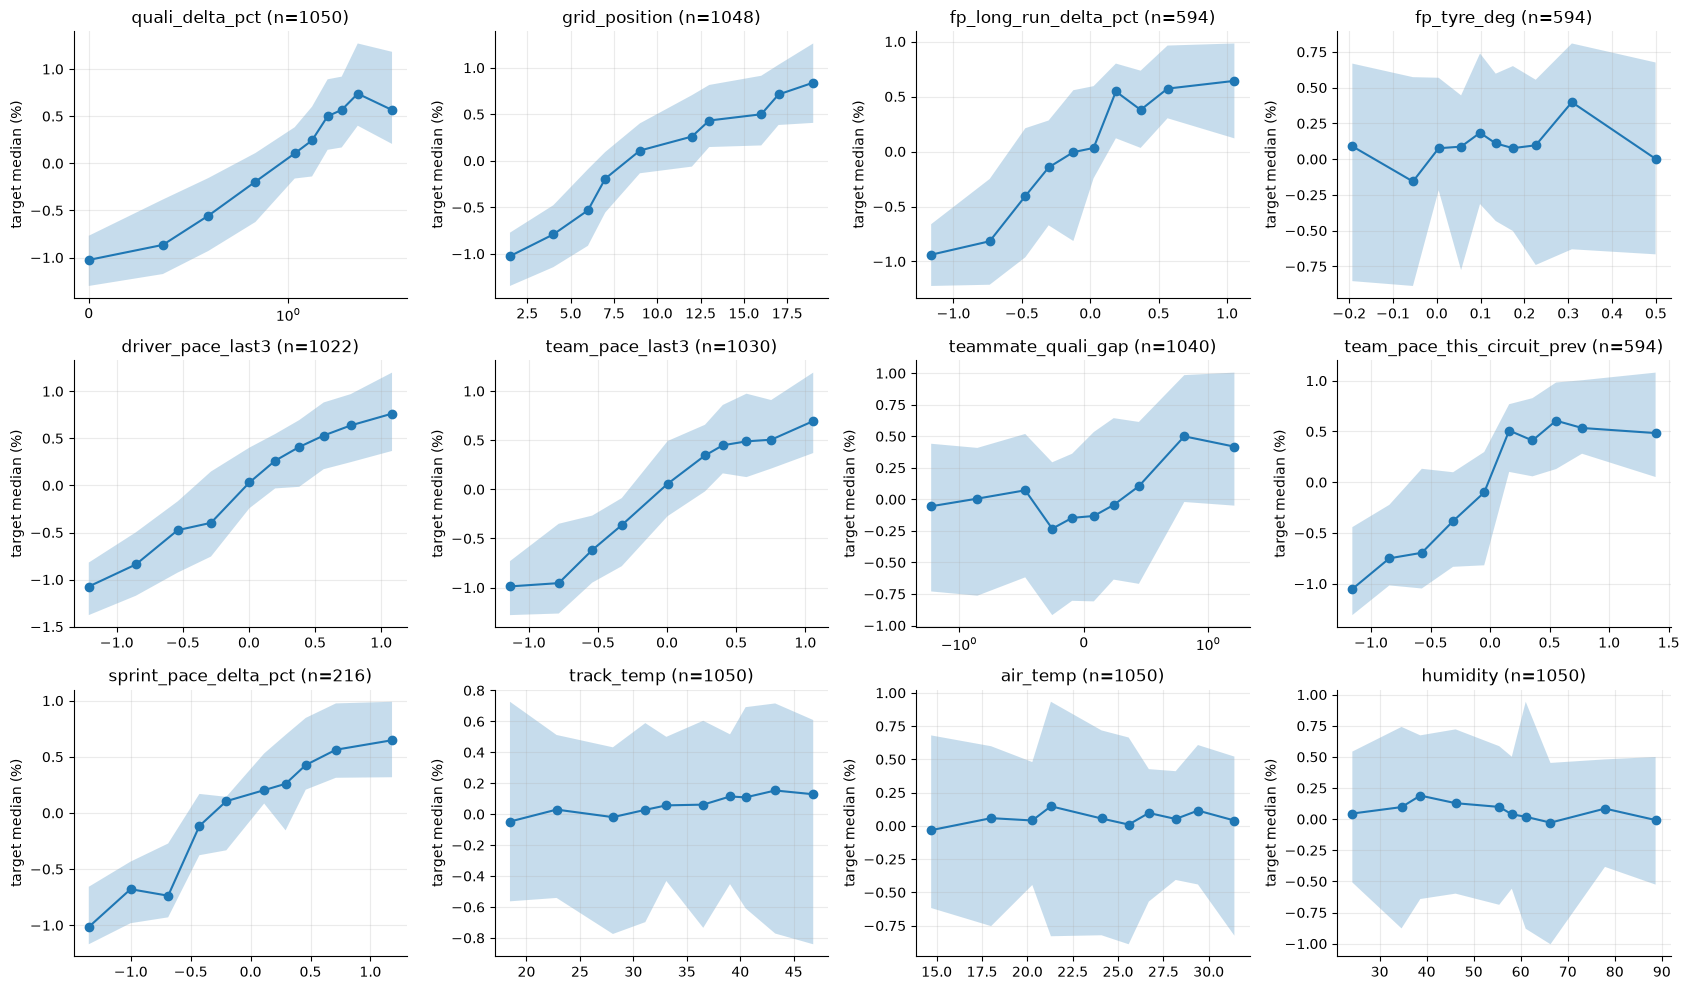

In [4]:
panels = [
    "quali_delta_pct",
    "grid_position",
    "fp_long_run_delta_pct",
    "fp_tyre_deg",
    "driver_pace_last3",
    "team_pace_last3",
    "teammate_quali_gap",
    "team_pace_this_circuit_prev",
    "sprint_pace_delta_pct",
    "track_temp",
    "air_temp",
    "humidity",
]
fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for ax, column in zip(axes.ravel(), panels, strict=True):
    part = valid[[column, TARGET]].dropna()
    bins = pd.qcut(part[column], 10, duplicates="drop")
    g = part.groupby(bins, observed=True)
    x = g[column].median()
    ax.fill_between(x, g[TARGET].quantile(0.25), g[TARGET].quantile(0.75), alpha=0.25)
    ax.plot(x, g[TARGET].median(), "o-")
    ax.set(title=f"{column} (n={len(part)})", ylabel="target median (%)")
    if column in ("quali_delta_pct", "teammate_quali_gap"):
        ax.set_xscale("symlog", linthresh=1)
plt.tight_layout()
plt.show()

In [5]:
for column in ("rain_flag", "is_sprint_weekend", "reached_q3"):
    g = valid.groupby(column)[TARGET].agg(["size", "median", "mean", "std"]).round(3)
    print(column)
    print(g.to_string(), "\n")

rain_flag
           size  median   mean    std
rain_flag                            
0.0         805   0.061  0.009  0.877
1.0         245   0.028  0.105  1.349 

is_sprint_weekend
                   size  median   mean    std
is_sprint_weekend                            
0.0                 791   0.057  0.041  1.074
1.0                 259   0.061  0.002  0.772 

reached_q3
            size  median   mean    std
reached_q3                            
0.0          521   0.521  0.548  0.669
1.0          529  -0.535 -0.478  1.026 



## 3. The target by circuit type

In [6]:
by_type = valid.groupby("circuit_type")[TARGET].agg(["size", "median", "mean", "std"]).round(3)
print(by_type.to_string())
groups = [g[TARGET].to_numpy() for _, g in valid.groupby("circuit_type")]
h = stats.kruskal(*groups)
eta2 = (h.statistic - len(groups) + 1) / (len(valid) - len(groups))
print(f"\nKruskal-Wallis H {h.statistic:.2f}, p {h.pvalue:.3f}, epsilon-squared {eta2:.4f}")
for other in ("street", "hybrid"):

    def diff(frame, other=other):
        return (
            frame.loc[frame["circuit_type"] == other, TARGET].median()
            - frame.loc[frame["circuit_type"] == "permanent", TARGET].median()
        )

    print(f"median target, {other} minus permanent: {diff(valid):.3f}", race_bootstrap(diff, draws=500))
team_type = valid.groupby(["team", "circuit_type"])[TARGET].median().unstack().round(2)
print("\nmedian target by team and circuit type:")
print(team_type.to_string())

              size  median   mean    std
circuit_type                            
hybrid         166   0.102  0.024  0.889
permanent      659   0.029  0.024  1.035
street         225   0.090  0.057  1.010

Kruskal-Wallis H 0.89, p 0.642, epsilon-squared -0.0011


median target, street minus permanent: 0.062 [-0.012  0.137]


median target, hybrid minus permanent: 0.073 [-0.091  0.228]

median target by team and circuit type:
circuit_type     hybrid  permanent  street
team                                      
Alpine             0.26       0.26    0.40
Aston Martin       0.16       0.10    0.12
Ferrari           -0.52      -0.78   -0.82
Haas F1 Team       0.43       0.46    0.47
Kick Sauber        0.59       0.69    1.16
McLaren           -1.06      -0.80   -0.42
Mercedes          -0.49      -0.58   -0.59
RB                 0.34       0.36    0.58
Red Bull Racing   -0.83      -0.96   -1.08
Williams           0.63       0.50    0.53


## 4. Interactions

The scope document asks whether `grid_position` means the same on every kind of circuit. Spearman of the
qualifying position and of the capped qualifying gap against the target inside each group, then a linear check
of whether the products add anything to the main effects (cross-validated MAE, five expanding folds over whole
races as in `02`).

In [7]:
rows = []
for column in ("grid_position", "quali_cap3"):
    for key in ("circuit_type", "rain_flag", "is_sprint_weekend"):
        for level, part in valid.groupby(key):
            low, high = race_bootstrap(spearman_of(column), part, 300)
            rows.append(
                {
                    "feature": column,
                    "by": key,
                    "level": level,
                    "n": len(part),
                    "spearman": spearman_of(column)(part),
                    "ci_low": low,
                    "ci_high": high,
                }
            )
print(pd.DataFrame(rows).round(3).to_string(index=False))

      feature                by     level   n  spearman  ci_low  ci_high
grid_position      circuit_type    hybrid 166     0.727   0.651    0.815
grid_position      circuit_type permanent 659     0.749   0.708    0.789
grid_position      circuit_type    street 225     0.752   0.643    0.838
grid_position         rain_flag       0.0 805     0.767   0.731    0.801
grid_position         rain_flag       1.0 245     0.670   0.604    0.744
grid_position is_sprint_weekend       0.0 791     0.742   0.697    0.785
grid_position is_sprint_weekend       1.0 259     0.759   0.701    0.812
   quali_cap3      circuit_type    hybrid 166     0.665   0.497    0.803
   quali_cap3      circuit_type permanent 659     0.699   0.645    0.754
   quali_cap3      circuit_type    street 225     0.772   0.646    0.843
   quali_cap3         rain_flag       0.0 805     0.761   0.723    0.803
   quali_cap3         rain_flag       1.0 245     0.577   0.474    0.700
   quali_cap3 is_sprint_weekend       0.0 791     0

In [8]:
from sklearn.model_selection import TimeSeriesSplit  # noqa: E402


def design(frame, terms):
    cols = {}
    if "cap" in terms:
        cols["cap"] = frame["quali_cap3"]
    if "grid" in terms:
        cols["grid"] = frame["grid_position"]
    if "type" in terms:
        for level in ("hybrid", "street"):
            cols[level] = (frame["circuit_type"] == level).astype(float)
    if "cap*type" in terms:
        for level in ("hybrid", "street"):
            cols["cap*" + level] = frame["quali_cap3"] * (frame["circuit_type"] == level)
    if "grid*type" in terms:
        for level in ("hybrid", "street"):
            cols["grid*" + level] = frame["grid_position"] * (frame["circuit_type"] == level)
    if "rain" in terms:
        cols["rain"] = frame["rain_flag"]
    if "cap*rain" in terms:
        cols["cap*rain"] = frame["quali_cap3"] * frame["rain_flag"]
    return np.column_stack([np.ones(len(frame))] + list(cols.values()))


def cv_mae(frame, terms):
    frame = (
        frame.dropna(subset=["quali_delta_pct", "grid_position"]).sort_values(["year", "round"]).reset_index(drop=True)
    )
    order = frame[["year", "round"]].drop_duplicates().reset_index(drop=True)
    index = frame.merge(order.reset_index(names="race"), on=["year", "round"])["race"].to_numpy()
    x, y = design(frame, terms), frame[TARGET].to_numpy()
    scores = []
    for train_races, test_races in TimeSeriesSplit(n_splits=load_config().cv.folds).split(order):
        train, test = np.isin(index, train_races), np.isin(index, test_races)
        beta = np.linalg.lstsq(x[train], y[train], rcond=None)[0]
        scores.append(np.abs(y[test] - x[test] @ beta).mean())
    return np.mean(scores), np.std(scores)


models = {
    "capped quali gap": ["cap"],
    "+ grid_position": ["cap", "grid"],
    "+ circuit type": ["cap", "grid", "type"],
    "+ cap x circuit type": ["cap", "grid", "type", "cap*type"],
    "+ grid x circuit type": ["cap", "grid", "type", "grid*type"],
    "+ rain": ["cap", "grid", "rain"],
    "+ cap x rain": ["cap", "grid", "rain", "cap*rain"],
}
table = {}
for name, terms in models.items():
    table[name] = {
        "all valid": cv_mae(valid, terms)[0],
        "sd": cv_mae(valid, terms)[1],
        "15+ laps": cv_mae(firm, terms)[0],
        "sd (15+)": cv_mae(firm, terms)[1],
    }
print(pd.DataFrame(table).T.round(3).to_string())

                       all valid     sd  15+ laps  sd (15+)
capped quali gap           0.522  0.044     0.511     0.039
+ grid_position            0.482  0.040     0.452     0.035
+ circuit type             0.484  0.044     0.453     0.034
+ cap x circuit type       0.488  0.050     0.457     0.034
+ grid x circuit type      0.488  0.050     0.458     0.034
+ rain                     0.483  0.040     0.452     0.035
+ cap x rain               0.484  0.045     0.450     0.037


## 5. Correlation between features and VIF

Spearman between features (pairwise complete). VIF on standardised complete cases; the qualifying gap enters
capped at 3%. A VIF above 5 is worth a look, above 10 is a problem for a linear model; trees are not hurt, but
their importances split between correlated features.

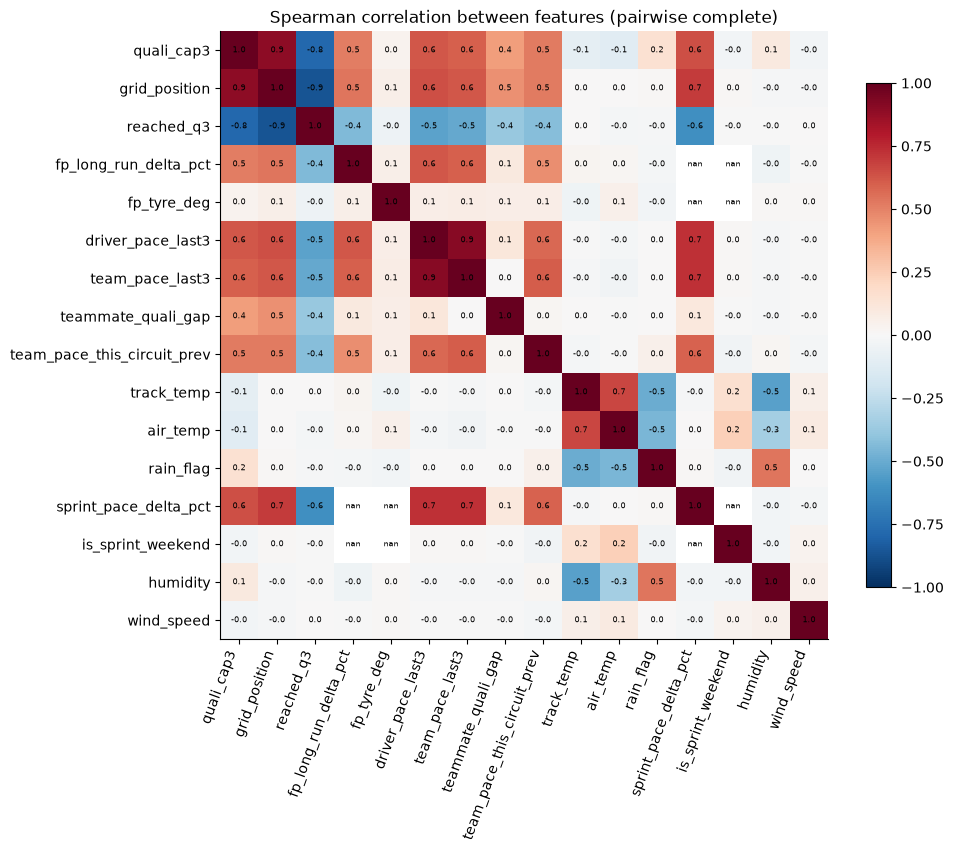

pairs with |Spearman| >= 0.5:
driver_pace_last3            team_pace_last3                0.91
quali_cap3                   grid_position                  0.90
grid_position                reached_q3                    -0.86
quali_cap3                   reached_q3                    -0.78
team_pace_last3              sprint_pace_delta_pct          0.73
driver_pace_last3            sprint_pace_delta_pct          0.73
grid_position                sprint_pace_delta_pct          0.70
track_temp                   air_temp                       0.67
quali_cap3                   sprint_pace_delta_pct          0.65
grid_position                driver_pace_last3              0.65
quali_cap3                   driver_pace_last3              0.62
grid_position                team_pace_last3                0.62
fp_long_run_delta_pct        driver_pace_last3              0.62
reached_q3                   sprint_pace_delta_pct         -0.62
team_pace_last3              team_pace_this_circuit_prev    

In [9]:
features = [
    "quali_cap3",
    "grid_position",
    "reached_q3",
    "fp_long_run_delta_pct",
    "fp_tyre_deg",
    "driver_pace_last3",
    "team_pace_last3",
    "teammate_quali_gap",
    "team_pace_this_circuit_prev",
    "track_temp",
    "air_temp",
    "rain_flag",
    "sprint_pace_delta_pct",
    "is_sprint_weekend",
    "humidity",
    "wind_speed",
]
rho = valid[features].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
image = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(features)), features, rotation=70, ha="right")
ax.set_yticks(range(len(features)), features)
ax.grid(False)
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, f"{rho.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(image, shrink=0.8)
ax.set_title("Spearman correlation between features (pairwise complete)")
plt.tight_layout()
plt.show()
pairs = rho.where(np.triu(np.ones(rho.shape, dtype=bool), 1)).stack()
strong = pairs[pairs.abs() >= 0.5].sort_values(key=abs, ascending=False)
print("pairs with |Spearman| >= 0.5:")
print(strong.round(2).to_string())

In [10]:
def vif(frame, columns):
    part = frame[columns].dropna()
    part = part.loc[:, part.std() > 0]  # a column that is constant on the complete cases has no VIF
    z = ((part - part.mean()) / part.std()).to_numpy()
    out = {}
    for i, name in enumerate(part.columns):
        others = np.delete(z, i, axis=1)
        beta = np.linalg.lstsq(others, z[:, i], rcond=None)[0]
        r2 = 1 - ((z[:, i] - others @ beta) ** 2).sum() / (z[:, i] ** 2).sum()
        out[name] = 1 / (1 - r2)
    return pd.Series(out).round(2), len(part), np.linalg.cond(z)


core = [
    "quali_cap3",
    "grid_position",
    "reached_q3",
    "driver_pace_last3",
    "team_pace_last3",
    "teammate_quali_gap",
    "track_temp",
    "air_temp",
    "rain_flag",
    "is_sprint_weekend",
]
sets = {
    "core (Saturday + form + weather)": core,
    "core + humidity, wind_speed": core + ["humidity", "wind_speed"],
    "core + FP2 and previous-year circuit": core
    + ["fp_long_run_delta_pct", "fp_tyre_deg", "team_pace_this_circuit_prev"],
}
result = {}
for name, columns in sets.items():
    values, n, cond = vif(valid, columns)
    print(f"{name}: {n} complete rows, condition number {cond:.1f}")
    result[name] = values
print(pd.DataFrame(result).round(2).to_string())

core (Saturday + form + weather): 1010 complete rows, condition number 6.9
core + humidity, wind_speed: 1010 complete rows, condition number 7.0
core + FP2 and previous-year circuit: 344 complete rows, condition number 9.4
                             core (Saturday + form + weather)  core + humidity, wind_speed  core + FP2 and previous-year circuit
air_temp                                                 2.32                         2.38                                  2.10
driver_pace_last3                                        4.55                         4.55                                  8.54
fp_long_run_delta_pct                                     NaN                          NaN                                  1.58
fp_tyre_deg                                               NaN                          NaN                                  1.10
grid_position                                            8.55                         8.71                                 11.88
hum

## 6. Leakage suspects

Every feature must be known at the end of Saturday, and the form features must use only earlier races. First the
timing of each source; then an independent recomputation of the form features from earlier valid rows only.

In [11]:
timing = pd.DataFrame(
    [
        ("quali_delta_pct, grid_position, reached_q3", "Q `session_result`", "Saturday"),
        ("teammate_quali_gap", "Q `session_result`", "Saturday"),
        ("track_temp, air_temp, rain_flag (and humidity, wind_speed)", "Q `weather`", "Saturday, during Q"),
        ("fp_long_run_delta_pct, fp_tyre_deg", "FP2 laps, stints, race control", "Friday"),
        ("sprint_pace_delta_pct", "Sprint `S` laps", "Saturday (sprint weekends)"),
        ("driver_pace_last3, team_pace_last3", "targets of earlier races", "earlier weekends"),
        ("team_pace_this_circuit_prev", "targets of the previous year", "earlier weekends"),
        ("circuit_type, is_sprint_weekend", "`circuits.yml`, the calendar", "known in advance"),
    ],
    columns=["features", "source", "known"],
)
print(timing.to_string(index=False))

                                                  features                         source                      known
                quali_delta_pct, grid_position, reached_q3             Q `session_result`                   Saturday
                                        teammate_quali_gap             Q `session_result`                   Saturday
track_temp, air_temp, rain_flag (and humidity, wind_speed)                    Q `weather`         Saturday, during Q
                        fp_long_run_delta_pct, fp_tyre_deg FP2 laps, stints, race control                     Friday
                                     sprint_pace_delta_pct                Sprint `S` laps Saturday (sprint weekends)
                        driver_pace_last3, team_pace_last3       targets of earlier races           earlier weekends
                               team_pace_this_circuit_prev   targets of the previous year           earlier weekends
                           circuit_type, is_sprint_weekend   `ci

In [12]:
ordered = valid.sort_values(["year", "round"])
driver_form = ordered.groupby("driver")[TARGET].transform(lambda s: s.shift().rolling(3, min_periods=1).mean())
team_race = ordered.groupby(["team", "year", "round"], sort=False)[TARGET].mean().reset_index()
team_race["form"] = team_race.groupby("team")[TARGET].transform(lambda s: s.shift().rolling(3, min_periods=1).mean())
team_form = ordered.merge(team_race[["team", "year", "round", "form"]], on=["team", "year", "round"], how="left")[
    "form"
]
team_form.index = ordered.index
gap_driver = (driver_form - ordered["driver_pace_last3"]).abs().max()
gap_team = (team_form - ordered["team_pace_last3"]).abs().max()
print(f"driver_pace_last3 against an independent shift-and-roll: max abs difference {gap_driver:.2e}")
print(f"team_pace_last3 against an independent shift-and-roll: max abs difference {gap_team:.2e}")
print(
    "NaN pattern equal:",
    bool((driver_form.isna() == ordered["driver_pace_last3"].isna()).all()),
    bool((team_form.isna() == ordered["team_pace_last3"].isna()).all()),
)
top = corr["spearman"].abs().sort_values(ascending=False)
print(
    "\nhighest |Spearman| with the target:", top.head(3).round(3).to_dict(), "(a value above ~0.8 would be a suspect)"
)

driver_pace_last3 against an independent shift-and-roll: max abs difference 0.00e+00
team_pace_last3 against an independent shift-and-roll: max abs difference 8.88e-16
NaN pattern equal: True True

highest |Spearman| with the target: {'grid_position': 0.745, 'sprint_pace_delta_pct': 0.734, 'driver_pace_last3': 0.709} (a value above ~0.8 would be a suspect)


## Figures for the summary

In [13]:
FIGURES = ROOT / "docs" / "eda" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.savefig(FIGURES / name, dpi=100, bbox_inches="tight")
    plt.close(fig)
    print("saved", (FIGURES / name).relative_to(ROOT))


order = corr["spearman"].abs().sort_values().index
fig, ax = plt.subplots(figsize=(8.5, 5.4))
values = corr.loc[order, "spearman"]
errors = [values - corr.loc[order, "ci_low"], corr.loc[order, "ci_high"] - values]
colors = ["C7" if name in EXPLORATION_ONLY else "C0" for name in order]
ax.barh(range(len(order)), values, xerr=errors, color=colors, error_kw={"lw": 1})
ax.set_yticks(range(len(order)), [f"{name} (n={corr.loc[name, 'n']})" for name in order])
ax.axvline(0, color="k", lw=0.8)
ax.set(title="Spearman with the target, 95% interval over races\n(grey: exploration only)", xlabel="Spearman")
save(fig, "07_correlation_with_target.png")

fig, ax = plt.subplots(figsize=(10, 8.5))
image = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(features)), features, rotation=70, ha="right")
ax.set_yticks(range(len(features)), features)
ax.grid(False)
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, f"{rho.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(image, shrink=0.8)
ax.set_title("Spearman correlation between features (pairwise complete)")
save(fig, "08_feature_correlation.png")

saved docs/eda/figures/07_correlation_with_target.png


saved docs/eda/figures/08_feature_correlation.png


## Findings

Suggested decisions (they reach `DECISIONS.md` in step 13, after the review of the summary):

1. **`humidity` and `wind_speed` are not promoted to features.** Their Spearman with the target is -0.02 [-0.05, 0.02] and -0.03 [-0.07, 0.00], and they add nothing to the other weather columns (VIF 1.8 and 1.0). They stay out of the catalog of 15.
2. **No column is dropped and no feature is merged yet.** Five features have a marginal relation close to 0 (`fp_tyre_deg` 0.05 [-0.02, 0.13]; `track_temp` 0.01; `air_temp` -0.01; `is_sprint_weekend` -0.01; `rain_flag` 0.00, all with intervals that include 0), but a marginal correlation does not say a feature is useless inside a model (rain weakens the qualifying relation, below). Whether they stay is a feature-selection question for Phase 4, measured with the models, not read from this table.

What the data says, with no decision attached:

- **Saturday and form features carry the signal.** Spearman with the target, with the race-resampled interval: `grid_position` 0.745 [0.71, 0.78], `sprint_pace_delta_pct` 0.734 [0.64, 0.80] (only on the 216 rows of sprint weekends), `driver_pace_last3` 0.709, `quali_delta_pct` 0.708, `team_pace_last3` 0.701, `reached_q3` -0.645, `fp_long_run_delta_pct` 0.575 (594 rows), `team_pace_this_circuit_prev` 0.554 (594 rows). `teammate_quali_gap` is weak (0.206).
- **The Pearson values are held down by a few rows, Spearman is not.** `quali_delta_pct` has Pearson 0.31 against Spearman 0.71 because of the very large gaps; capped at 3% its Pearson is 0.59 and its Spearman is unchanged (0.709). With 15 or more clean laps `grid_position` goes from Pearson 0.61 to 0.72 and `fp_long_run_delta_pct` from 0.30 to 0.51: the nine rows below 15 laps weigh more than their number, as `02` found.
- **The relations are monotone, and several saturate.** The binned medians climb with the qualifying position and the qualifying gap and flatten at the back (the gap beyond about 2%); `fp_long_run_delta_pct` and `team_pace_this_circuit_prev` rise up to about 0 and then level off at +0.5; the two form features run close to a straight line. `fp_tyre_deg`, the temperatures and humidity are flat across their whole range, and `teammate_quali_gap` only turns up at its high end.
- **Circuit type does not move the target.** Kruskal-Wallis H 0.89, p 0.64, effect size about 0; street minus permanent +0.06 [-0.01, 0.14], hybrid minus permanent +0.07 [-0.09, 0.23]. By team the medians barely change with the type (McLaren -1.06 on hybrid and -0.42 on street, Kick Sauber 0.69 on permanent and 1.16 on street, are the only moves, on a few races each).
- **Rain weakens the qualifying relation, but a straight line cannot use it.** The Spearman of the capped gap is 0.58 [0.47, 0.70] in races with rain in Q against 0.76 [0.72, 0.80] without it (for `grid_position` 0.67 against 0.77). Adding rain, or its product with the gap, leaves the cross-validated MAE where it was (0.483 and 0.484 against 0.482; 0.452 and 0.450 on 15+ laps). Circuit type, and its products with the gap and the position, add nothing either (0.484 to 0.488). A tree model may still use the rain interaction; that is for Phase 4.
- **`grid_position` adds to the qualifying gap.** The line on the capped gap alone scores a CV MAE of 0.522 (0.511 on 15+ laps); with `grid_position` it scores 0.482 (0.452). The 0.452 is the figure to beat for a linear model, against the 0.705 of the median dummy.
- **Collinearity is moderate and has a clear structure.** Spearman between features: `driver_pace_last3` with `team_pace_last3` 0.91; capped gap with `grid_position` 0.90; `grid_position` with `reached_q3` -0.86; gap with `reached_q3` -0.78. VIF on 1,010 complete rows: `grid_position` 8.6, capped gap 5.1, `team_pace_last3` 4.8, `driver_pace_last3` 4.6, `reached_q3` 4.1, the rest under 2.5; none above 10 (condition number 6.9). On the 344 rows that also have FP2 and the previous-year circuit, `grid_position` reaches 11.9 and the form and gap features 8.5 to 8.7. Ridge and ElasticNet handle this; for trees and SHAP the importance splits inside each group, so it is better to read it by family (qualifying, form).
- **No leakage found.** Every source is known by the end of Saturday (the sprint is a Saturday session; FP2 is Friday); the two form features match an independent shift-and-roll from earlier valid rows only (maximum difference 0 and 9e-16, same NaN pattern); the largest correlation with the target is 0.745, below the 0.8 that would raise suspicion.